### 03 — Preprocessing & Augmentation
BrainScan AI · MRI classification and detection
Goals
- Load the train.csv, validation.csv, and test.csv manifests from Notebook 02.
- Validate image paths and inspect the manifest.
- Resize images to a consistent size and normalize pixels to [0, 1].
- Apply augmentation to training images only.
- Visualize outputs and verify shapes/ranges.
Rules
1. This notebook does not split the data; Notebook 02 owns the 70/15/15 split.
2. Validation/test get deterministic preprocessing only—no random augmentation.
3. Never overwrite raw images or silently discard invalid files.
4. This starter augmentation is for classification. For YOLO, every geometric image transform must update bounding boxes identically. Do not use this image-only pipeline for detection labels.
5. MRI augmentation must be clinically sensible. Inspect samples and compare against a no-augmentation baseline.

### 1 - imports and configurations

In [44]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError
from IPython.display import display
import sys


# Locate the project root, whether Jupyter starts in the root or notebooks/
CURRENT_DIR = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        path
        for path in (CURRENT_DIR, *CURRENT_DIR.parents)
        if (path / "config" / "settings.py").is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise RuntimeError(
        "Project root not found. Expected config/settings.py "
        "in the current directory or one of its parents."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config import settings

# Use centralized settings
TRAIN_CSV = settings.TRAIN_MANIFEST_PATH
VAL_CSV = settings.VALIDATION_MANIFEST_PATH
TEST_CSV = settings.TEST_MANIFEST_PATH
MANIFESTS = {
    "train": settings.TRAIN_MANIFEST_PATH,
    "validation": settings.VALIDATION_MANIFEST_PATH,
    "test": settings.TEST_MANIFEST_PATH,

}
IMAGE_SIZE = (settings.IMAGE_SIZE, settings.IMAGE_SIZE)
BATCH_SIZE = settings.BATCH_SIZE
SEED = settings.RANDOM_STATE
random.seed(SEED)
np.random.seed(SEED)
print("Project root:", PROJECT_ROOT)
for name, path in MANIFESTS.items():
    print(f"{name}: {path} | exists={path.is_file()}")


# print("Project:", settings.PROJECT_NAME)
# print("Root:", settings.PROJECT_ROOT)
# print("Train manifest:", TRAIN_CSV)
# print("Validation manifest:", VAL_CSV)
# print("Test manifest:", TEST_CSV)
# print("Image size:", IMAGE_SIZE)
# print("Batch size:", BATCH_SIZE)
# print("Random state:", SEED)




Project root: /home/moali/projects/brainscan_ai
train: /home/moali/projects/brainscan_ai/data/splits/train.csv | exists=True
validation: /home/moali/projects/brainscan_ai/data/splits/validation.csv | exists=True
test: /home/moali/projects/brainscan_ai/data/splits/test.csv | exists=True


### 2. Load and inspect split manifests

In [45]:
missing = [str(p) for p in MANIFESTS.values() if not p.is_file()]
if missing:
    raise FileNotFoundError("Missing split file(s):\n- " + "\n- ".join(missing) + "\nRun Notebook 02 first.")
splits = {name: pd.read_csv(path) for name, path in MANIFESTS.items()}
for name, frame in splits.items():
    print(f"\n{name.upper()}: {len(frame):,} rows")
    print("Columns:", frame.columns.tolist())
    display(frame.head())


TRAIN: 4,916 rows
Columns: ['image_path', 'relative_path', 'label', 'extension', 'file_size_bytes', 'width', 'height', 'image_mode', 'is_valid']


,image_path,relative_path,label,extension,file_size_bytes,width,height,image_mode,is_valid
0,/home/moali/projects/brainscan_ai/data/raw/gli...,glioma/Te-gl_0274.jpg,glioma,.jpg,22680,512,512,L,True
1,/home/moali/projects/brainscan_ai/data/raw/not...,notumor/Tr-no_0984.jpg,notumor,.jpg,12060,236,236,RGB,True
2,/home/moali/projects/brainscan_ai/data/raw/men...,meningioma/Tr-me_1092.jpg,meningioma,.jpg,25839,512,512,L,True
3,/home/moali/projects/brainscan_ai/data/raw/gli...,glioma/Te-gl_0273.jpg,glioma,.jpg,23693,512,512,L,True
4,/home/moali/projects/brainscan_ai/data/raw/pit...,pituitary/Tr-pi_1247.jpg,pituitary,.jpg,26616,512,512,L,True



VALIDATION: 1,053 rows
Columns: ['image_path', 'relative_path', 'label', 'extension', 'file_size_bytes', 'width', 'height', 'image_mode', 'is_valid']


,image_path,relative_path,label,extension,file_size_bytes,width,height,image_mode,is_valid
0,/home/moali/projects/brainscan_ai/data/raw/gli...,glioma/Te-gl_0180.jpg,glioma,.jpg,20756,512,512,L,True
1,/home/moali/projects/brainscan_ai/data/raw/pit...,pituitary/Tr-pi_0128.jpg,pituitary,.jpg,40866,512,512,RGB,True
2,/home/moali/projects/brainscan_ai/data/raw/gli...,glioma/Te-gl_0146.jpg,glioma,.jpg,19399,512,512,L,True
3,/home/moali/projects/brainscan_ai/data/raw/gli...,glioma/Tr-gl_0035.jpg,glioma,.jpg,24171,512,512,RGB,True
4,/home/moali/projects/brainscan_ai/data/raw/men...,meningioma/Te-me_0224.jpg,meningioma,.jpg,23939,512,512,L,True



TEST: 1,054 rows
Columns: ['image_path', 'relative_path', 'label', 'extension', 'file_size_bytes', 'width', 'height', 'image_mode', 'is_valid']


,image_path,relative_path,label,extension,file_size_bytes,width,height,image_mode,is_valid
0,/home/moali/projects/brainscan_ai/data/raw/men...,meningioma/Tr-me_0617.jpg,meningioma,.jpg,28082,512,512,RGB,True
1,/home/moali/projects/brainscan_ai/data/raw/pit...,pituitary/Te-pi_0163.jpg,pituitary,.jpg,22226,512,512,L,True
2,/home/moali/projects/brainscan_ai/data/raw/not...,notumor/Tr-no_0083.jpg,notumor,.jpg,18977,236,216,RGB,True
3,/home/moali/projects/brainscan_ai/data/raw/gli...,glioma/Tr-gl_1180.jpg,glioma,.jpg,20257,512,512,L,True
4,/home/moali/projects/brainscan_ai/data/raw/gli...,glioma/Tr-gl_0479.jpg,glioma,.jpg,23615,512,512,L,True


### 3. Configure manifest columns

In [46]:
IMAGE_COL = "image_path"
LABEL_COL = "label"

def resolve_path(value):
    p = Path(str(value)).expanduser()
    return p.resolve() if p.is_absolute() else (PROJECT_ROOT / p).resolve()


for name, frame in splits.items():
    if IMAGE_COL not in frame.columns:
        raise KeyError(f"{name}: '{IMAGE_COL}' not found. Available: {frame.columns.tolist()}")

    if LABEL_COL is not None and LABEL_COL not in frame.columns:
        raise KeyError(f"{name}: '{LABEL_COL}' not found. Available: {frame.columns.tolist()}")

    frame["_resolved_path"] = frame[IMAGE_COL].map(resolve_path)
    frame["_exists"] = frame["_resolved_path"].map(lambda p:p.is_file())
    print(f"{name}: {int(frame['_exists'].sum())}/{len(frame)} paths exist")
    if (~frame["_exists"]).any():
        display(frame.loc[~frame["_exists"], [IMAGE_COL]].head(10))

train: 4916/4916 paths exist
validation: 1053/1053 paths exist
test: 1054/1054 paths exist


### 4. Check readability and split leakage

In [47]:
def is_readable(path):
    try:
        with Image.open(path) as im:
            im.verify()
        return True
    except (UnidentifiedImageError, OSError, ValueError):
        return False

for name, frame in splits.items():
    frame["_readable"] = False
    mask = frame["_exists"]
    frame.loc[mask, "_readable"] = frame.loc[mask, "_resolved_path"].map(is_readable)
    print(f"{name}: {int(frame['_readable'].sum())}/{len(frame)} readable")

path_sets = {name: set(f.loc[f["_exists"], "_resolved_path"].astype(str)) for name, f in splits.items()}
for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    overlap = path_sets[a] & path_sets[b]
    print(f"Path overlap {a}/{b}: {len(overlap)}")
    if overlap:
        raise ValueError(f"Data leakage: image paths overlap between {a} and {b}.")

train: 4916/4916 readable
validation: 1053/1053 readable
test: 1054/1054 readable
Path overlap train/validation: 0
Path overlap train/test: 0
Path overlap validation/test: 0


### 5. Inspect class balance


TRAIN class counts


,count
class,
notumor,1400
pituitary,1230
meningioma,1151
glioma,1135



VALIDATION class counts


,count
class,
notumor,300
pituitary,263
meningioma,247
glioma,243



TEST class counts


,count
class,
notumor,300
pituitary,264
meningioma,247
glioma,243


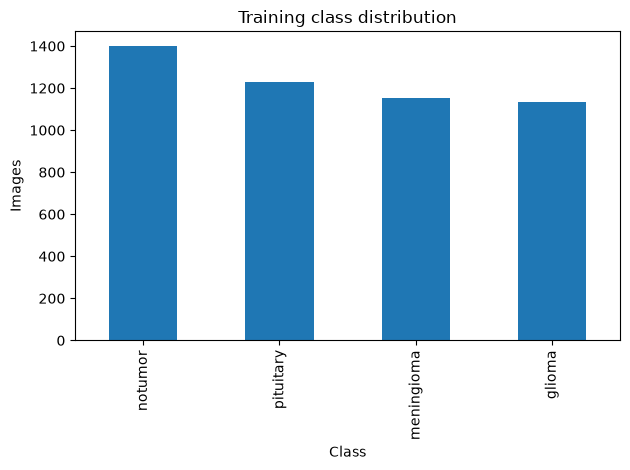

In [48]:
if LABEL_COL is not None:
    for name, frame in splits.items():
        print(f"\n{name.upper()} class counts")
        display(frame[LABEL_COL].value_counts(dropna=False).rename_axis("class").to_frame("count"))
    ax = splits["train"][LABEL_COL].value_counts().plot(kind="bar", title="Training class distribution")
    ax.set_xlabel("Class")
    ax.set_ylabel("Images")
    plt.tight_layout()
    plt.show()
else:
    print("No classification label configured; skipping class counts.")

### 6. Deterministic preprocessing
Convert to RGB, resize, and scale pixel values to [0, 1]. This function contains no random augmentation.

In [49]:
def preprocess_image(image_path, image_size=IMAGE_SIZE):
    """
    Return float32 RGB image with shape (height, width, 3) and values in [0,1]

    """
    with Image.open(image_path) as im:
        im = im.convert("RGB")
        im = im.resize((image_size[1], image_size[0]), Image.Resampling.BILINEAR)
        arr = np.asarray(im, dtype=np.float32) / 255.0
    return arr

valid_train = splits["train"].loc[splits["train"]["_exists"] & splits["train"]["_readable"]]

if valid_train.empty:
    raise ValueError("No readable training images. Check paths, file extensions, and dataset extraction.")
example_row = valid_train.iloc[0]
example = preprocess_image(example_row["_resolved_path"])
print("Image:", example_row[IMAGE_COL])
print("Shape:", example.shape, "dtype:", example.dtype)
print("Pixel min/max:", float(example.min()), float(example.max()))
assert example.shape == (*IMAGE_SIZE, 3)
assert example.dtype == np.float32
assert 0 <= example.min() <= example.max() <= 1

Image: /home/moali/projects/brainscan_ai/data/raw/glioma/Te-gl_0274.jpg
Shape: (224, 224, 3) dtype: float32
Pixel min/max: 0.0 0.929411768913269


### 7. Visualize preprocessed examples

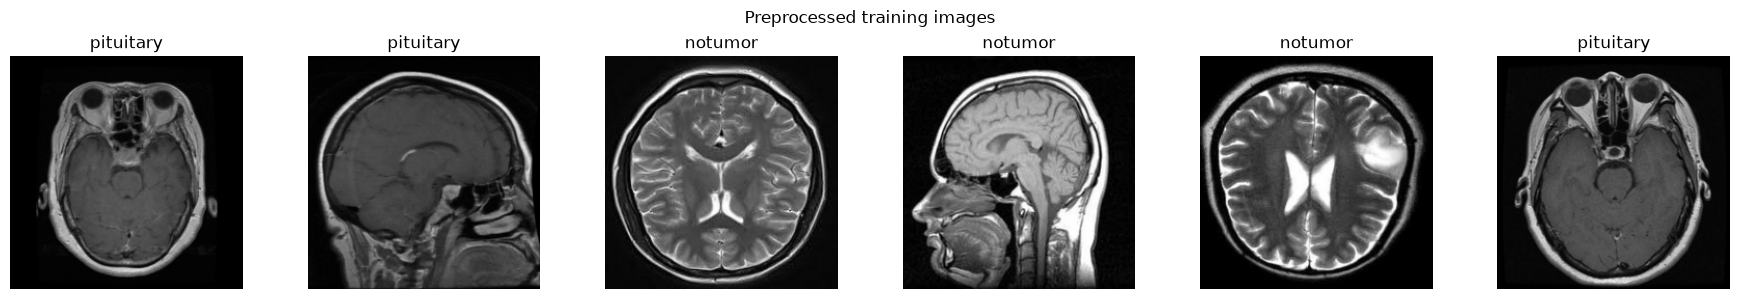

In [50]:
n = min(6, len(valid_train))
sample = valid_train.sample(n=n, random_state=SEED)
fig, axes = plt.subplots(1, n, figsize=(3*n, 3))
if n == 1:
    axes = [axes]
for ax, (_, row) in zip(axes, sample.iterrows()):
    ax.imshow(preprocess_image(row["_resolved_path"]))
    ax.set_title(str(row[LABEL_COL]) if LABEL_COL is not None else "MRI")
    ax.axis("off")
plt.suptitle("Preprocessed training images")
plt.tight_layout()
plt.show()

### 8. Define training-only augmentation
Conservative TensorFlow/Keras example: slight contrast and brightness variation. These are stochastic and should be evaluated—not assumed to improve performance. This is an image-only classification pipeline, not a YOLO detection augmentation pipeline.

In [51]:
try:
    import tensorflow as tf
except ImportError as exc:
        raise ImportError("TensorFlow is required for this section. Install the compatible project dependency in your active environment.") from exc

tf.random.set_seed(SEED)
augmentation = tf.keras.Sequential([
      tf.keras.layers.RandomContrast(0.10),
      tf.keras.layers.RandomBrightness(0.05, value_range=(0.0, 1.0)),
], name="classification_augmentation")

def augment_training_image(image):
      tensor = tf.convert_to_tensor(image, dtype=tf.float32)
      out = augmentation(tensor[tf.newaxis, ...], training=True)[0]
      return tf.clip_by_value(out, 0.0, 1.0).numpy()

augmented = augment_training_image(example)
print("Original:", example.shape, float(example.min()), float(example.max()))
print("Augmented:", augmented.shape, float(augmented.min()), float(augmented.max()))

Original: (224, 224, 3) 0.0 0.929411768913269
Augmented: (224, 224, 3) 0.047915589064359665 1.0


### 9. Compare original and augmented

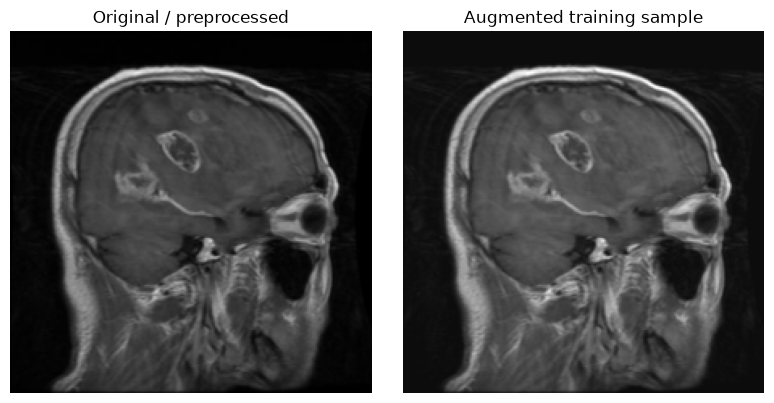

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(example); axes[0].set_title("Original / preprocessed"); axes[0].axis("off")
axes[1].imshow(augmented); axes[1].set_title("Augmented training sample"); axes[1].axis("off")
plt.tight_layout(); plt.show()

### 10. Create tf.data pipelines
Augmentation is enabled only for train_ds. Validation and test pipelines use deterministic preprocessing only. This section is for classification manifests with labels.

In [53]:
if LABEL_COL is None:
    print("Skipping classification datasets because LABEL_COL is None.")
else:
    clean = {}
    for name, frame in splits.items():
        clean[name] = frame.loc[frame["_exists"] & frame["_readable"]].copy()
        if clean[name].empty:
            raise ValueError(f"No readable images in {name}; investigate before training.")

    class_names = sorted(pd.concat([f[LABEL_COL].astype(str) for f in clean.values()]).unique().tolist())
    class_to_id = {name: i for i, name in enumerate(class_names)}
    print("Class mapping:", class_to_id)

    def load_one(path, label, do_augment=False):
        image_bytes = tf.io.read_file(path)
        image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
        image.set_shape([None, None, 3])
        image = tf.image.resize(image, IMAGE_SIZE, method="bilinear")
        image = tf.cast(image, tf.float32) / 255.0
        if do_augment:
            image = augmentation(image[tf.newaxis, ...], training=True)[0]
            image = tf.clip_by_value(image, 0.0, 1.0)
        return image, label

    def make_dataset(frame, do_augment=False, shuffle=False):
        paths = frame["_resolved_path"].astype(str).to_numpy()
        labels = frame[LABEL_COL].astype(str).map(class_to_id).to_numpy(dtype=np.int32)
        ds = tf.data.Dataset.from_tensor_slices((paths, labels))
        if shuffle:
            ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.map(lambda p, y: load_one(p, y, do_augment), num_parallel_calls=tf.data.AUTOTUNE)
        return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

    train_ds = make_dataset(clean["train"], do_augment=True, shuffle=True)
    validation_ds = make_dataset(clean["validation"], do_augment=False)
    test_ds = make_dataset(clean["test"], do_augment=False)

    for name, ds in [("train", train_ds), ("validation", validation_ds), ("test", test_ds)]:
        images, labels = next(iter(ds.take(1)))
        print(name, "batch:", images.shape, labels.shape, "pixel range:", float(tf.reduce_min(images)), float(tf.reduce_max(images)))

Class mapping: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
train batch: (32, 224, 224, 3) (32,) pixel range: 0.0 1.0
validation batch: (32, 224, 224, 3) (32,) pixel range: 0.0 0.999743640422821
test batch: (32, 224, 224, 3) (32,) pixel range: 0.0 1.0
